In [ ]:
#Connects Google Colab with Google Drive.
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#Defines folders where preprocessed audio files will be stored.
clean_real = "/content/drive/MyDrive/VocaTrust/clean_data/real"
clean_fake = "/content/drive/MyDrive/VocaTrust/clean_data/fake"

import os
os.makedirs(clean_real, exist_ok=True)
os.makedirs(clean_fake, exist_ok=True)

In [ ]:
#Loads audio
#Converts to mono
#Resamples to 16kHz
#Fixes duration to 3 seconds
#Saves processed audio

import librosa
import soundfile as sf
import numpy as np

def preprocess_audio(input_path, output_path, duration=3):
    try:
        # Load audio → mono + 16kHz
        audio, sr = librosa.load(input_path, sr=16000, mono=True)

        # Fix length (pad or trim)
        max_len = 16000 * duration  # 3 seconds

        if len(audio) < max_len:
            pad = max_len - len(audio)
            audio = np.pad(audio, (0, pad))
        else:
            audio = audio[:max_len]

        # Save as WAV
        sf.write(output_path, audio, 16000)

    except Exception as e:
        print("Error:", input_path)

In [ ]:
#These loops preprocess all real and fake audio samples and convert them into a standardized WAV format.”

real_path = "/content/drive/MyDrive/VocaTrust/data/real"

for file in os.listdir(real_path):
    if file.endswith(".wav") or file.endswith(".flac"):
        in_path = os.path.join(real_path, file)
        out_path = os.path.join(clean_real, file.split('.')[0] + ".wav")

        preprocess_audio(in_path, out_path)

In [ ]:
fake_path = "/content/drive/MyDrive/VocaTrust/data/fake"

for file in os.listdir(fake_path):
    if file.endswith(".wav") or file.endswith(".flac"):
        in_path = os.path.join(fake_path, file)
        out_path = os.path.join(clean_fake, file.split('.')[0] + ".wav")

        preprocess_audio(in_path, out_path)

In [ ]:
#This verifies that preprocessing was successful and all files follow the same format

import librosa
import os

sample = os.listdir(clean_real)[0]

y, sr = librosa.load(
    os.path.join(clean_real, sample),
    sr=None   # 🔥 IMPORTANT: don't resample
)

print("Sample rate:", sr)
print("Length:", len(y))

Sample rate: 16000
Length: 48000


In [ ]:
import os
import numpy as np
import librosa
from tqdm import tqdm
from sklearn.model_selection import train_test_split

In [ ]:
real_path = "/content/drive/MyDrive/VocaTrust/clean_data/real"
fake_path = "/content/drive/MyDrive/VocaTrust/clean_data/fake"

In [ ]:
#Converts audio into MFCC features
#Produces fixed-size feature matrix

def extract_mfcc(file_path, max_len=100):
    try:
        audio, sr = librosa.load(file_path, sr=16000)
        mfcc = librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=13)

        # Fix size
        if mfcc.shape[1] < max_len:
            pad = max_len - mfcc.shape[1]
            mfcc = np.pad(mfcc, ((0,0),(0,pad)), mode='constant')
        else:
            mfcc = mfcc[:, :max_len]

        return mfcc
    except:
        return None

In [ ]:
X = []   #X → stores MFCC features
y = []   #y → stores labels

# REAL = 1 Extracts MFCC from real audio Assigns label 1
for file in tqdm(os.listdir(real_path)):
    if file.endswith(".wav"):
        path = os.path.join(real_path, file)
        mfcc = extract_mfcc(path)
        if mfcc is not None:
            X.append(mfcc)
            y.append(1)

# FAKE = 0 Extracts MFCC from fake audio Assigns label 0
for file in tqdm(os.listdir(fake_path)):
    if file.endswith(".wav"):
        path = os.path.join(fake_path, file)
        mfcc = extract_mfcc(path)
        if mfcc is not None:
            X.append(mfcc)
            y.append(0)

100%|██████████| 25380/25380 [09:27<00:00, 44.70it/s]


In [ ]:
#The features and labels are converted into NumPy arrays for efficient processing.
X = np.array(X)
y = np.array(y)

# CNN models require an additional channel dimension similar to image processing
X = X[..., np.newaxis]

print("X shape:", X.shape)
print("y shape:", y.shape)

NameError: name 'X' is not defined

In [ ]:
#Splits data: 80% training , 20% testing

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
#Creates CNN architecture.
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(13,100,1)),
    MaxPooling2D((2,2)),

    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D((2,2)),

    Flatten(),
    Dense(64, activation='relu'),
    Dense(1, activation='sigmoid')
])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
#This configures the model training process.
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [ ]:
#Trains model using training data.
#The model learns patterns from labeled audio samples.
model.fit(
    X_train, y_train,
    epochs=5,
    batch_size=32,
    validation_data=(X_test, y_test)
)

Epoch 1/5
1140/1140 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9708 - loss: 0.1668 - val_accuracy: 0.9891 - val_loss: 0.0293
Epoch 2/5
1140/1140 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9921 - loss: 0.0236 - val_accuracy: 0.9940 - val_loss: 0.0179
Epoch 3/5
1140/1140 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.9936 - loss: 0.0188 - val_accuracy: 0.9959 - val_loss: 0.0118
Epoch 4/5
1140/1140 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9936 - loss: 0.0196 - val_accuracy: 0.9917 - val_loss: 0.0262
Epoch 5/5
1140/1140 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9956 - loss: 0.0134 - val_accuracy: 0.9977 - val_loss: 0.0083


In [ ]:
#This evaluates model performance on unseen data
loss, acc = model.evaluate(X_test, y_test)
print("Accuracy:", acc)

285/285 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9977 - loss: 0.0083
Accuracy: 0.9976973533630371


In [ ]:
#This function predicts the authenticity of an audio file and generates a voice integrity score.
def predict_audio(file_path):
    mfcc = extract_mfcc(file_path)
    mfcc = mfcc[np.newaxis, ..., np.newaxis]

    pred = model.predict(mfcc)[0][0]
    score = pred * 100

    if score > 80:
        label = "Genuine"
    elif score > 50:
        label = "Suspicious"
    else:
        label = "Fake"

    print("Score:", score)
    print("Result:", label)

In [ ]:
predict_audio("/content/drive/MyDrive/sample.wav")

In [ ]:
np.save("/content/drive/MyDrive/VocaTrust/X_train.npy", X_train)
np.save("/content/drive/MyDrive/VocaTrust/X_test.npy", X_test)
np.save("/content/drive/MyDrive/VocaTrust/y_train.npy", y_train)
np.save("/content/drive/MyDrive/VocaTrust/y_test.npy", y_test)

In [ ]:
#The trained model is saved for future use without retraining.
model.save("/content/drive/MyDrive/VocaTrust/model.h5")

In [ ]:
X_test = np.load("/content/drive/MyDrive/VocaTrust/X_test.npy")
y_test = np.load("/content/drive/MyDrive/VocaTrust/y_test.npy")

In [ ]:
#Reloads saved model.
from tensorflow.keras.models import load_model

model = load_model("/content/drive/MyDrive/VocaTrust/model.h5")

In [ ]:
np.save("/content/drive/MyDrive/VocaTrust/X.npy", X)
np.save("/content/drive/MyDrive/VocaTrust/y.npy", y)

In [ ]:
#Tests unseen sample.
import numpy as np

# Take one sample
sample = X_test[0]
sample = sample[np.newaxis, ...]   # reshape

# Predict
pred = model.predict(sample)[0][0]
score = pred * 100

# Label
if score > 80:
    result = "Genuine"
elif score > 50:
    result = "Suspicious"
else:
    result = "Fake"

print("Score:", score)
print("Predicted:", result)
print("Actual:", "Genuine" if y_test[0] == 1 else "Fake")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 450ms/step
Score: 0.027712667
Predicted: Fake
Actual: Fake


In [ ]:
#Tests multiple unseen samples.
for i in range(5):
    sample = X_test[i][np.newaxis, ...]

    pred = model.predict(sample)[0][0]
    score = pred * 100

    actual = "Genuine" if y_test[i] == 1 else "Fake"

    if score > 80:
        result = "Genuine"
    elif score > 50:
        result = "Suspicious"
    else:
        result = "Fake"

    print(f"\nSample {i+1}")
    print("Score:", round(score, 2))
    print("Predicted:", result)
    print("Actual:", actual)

NameError: name 'X_test' is not defined

In [ ]:
#Processes new audio files from folder.

import os
import librosa
import numpy as np
import soundfile as sf

# 🔹 PATH TO YOUR TEST FOLDER
test_folder = "/content/drive/MyDrive/VocaTrust/sample_test"

# 🔹 PREPROCESS FUNCTION
def preprocess_audio(file_path, duration=3):
    audio, sr = librosa.load(file_path, sr=16000, mono=True)
    max_len = 16000 * duration

    if len(audio) < max_len:
        audio = np.pad(audio, (0, max_len - len(audio)))
    else:
        audio = audio[:max_len]

    return audio

# 🔹 MFCC FUNCTION (use your existing one if already defined)
def extract_mfcc_from_audio(audio, sr=16000, max_len=100):
    mfcc = librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=13)

    if mfcc.shape[1] < max_len:
        pad = max_len - mfcc.shape[1]
        mfcc = np.pad(mfcc, ((0,0),(0,pad)), mode='constant')
    else:
        mfcc = mfcc[:, :max_len]

    return mfcc

# 🔹 LOOP THROUGH ALL FILES
for file in os.listdir(test_folder):

    if file.endswith(".wav") or file.endswith(".flac"):
        file_path = os.path.join(test_folder, file)

        # Preprocess
        audio = preprocess_audio(file_path)

        # Extract MFCC
        mfcc = extract_mfcc_from_audio(audio)
        mfcc = mfcc[np.newaxis, ..., np.newaxis]

        # Predict
        pred = model.predict(mfcc)[0][0]
        score = pred * 100

        # Label
        if score > 80:
            result = "Genuine"
        elif score > 50:
            result = "Suspicious"
        else:
            result = "Fake"

        # Print Output
        print("\nFile:", file)
        print("Score:", round(score, 2))
        print("Result:", result)

/tmp/ipykernel_519/3801621984.py:11: UserWarning: PySoundFile failed. Trying audioread instead.
  audio, sr = librosa.load(file_path, sr=16000, mono=True)
/usr/local/lib/python3.12/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step

File: sample.wav
Score: 100.0
Result: Genuine
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step

File: sample1.wav
Score: 1.47
Result: Fake
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step

File: sample2.wav
Score: 0.0
Result: Fake
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step

File: sample3.wav
Score: 100.0
Result: Genuine
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step

File: sample4.wav
Score: 100.0
Result: Genuine
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step

File: sample5.wav
Score: 100.0
Result: Genuine
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step

File: sample6.wav
Score: 99.99
Result: Genuine
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step

File: sample7.wav
Score: 0.35
Result: Fake


In [ ]:
#PHASE 2

In [ ]:
import os

BASE_DIR = "/content/drive/MyDrive/VocaTrust/Phase2"

folders = [
    "models",
    "history",
    "evaluation",
    "predictions",
    "checkpoints"
]

for folder in folders:
    os.makedirs(os.path.join(BASE_DIR, folder), exist_ok=True)

print("Phase2 folders created successfully.")

Phase2 folders created successfully.


In [ ]:
os.makedirs("/content/drive/MyDrive/VocaTrust/Phase2/logs", exist_ok=True)

print("Logs folder created.")

Logs folder created.


In [ ]:
# Phase 2 - Enhanced Voice Integrity Assessment

## Step 1: Improved CNN Architecture

In [ ]:
#IMPORT STATEMENTS
import os
import numpy as np
import librosa
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.callbacks import BackupAndRestore
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    CSVLogger
)

from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout,
    BatchNormalization
)

from tensorflow.keras.regularizers import l2

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint
)

from tensorflow.keras.optimizers import Adam

In [ ]:
## Improved CNN Model

In [ ]:
# ============================================
# Phase 2 - Improved CNN Model
# ============================================

improved_model = Sequential([

    # Block 1
    Conv2D(
        32,
        (3,3),
        activation='relu',
        padding='same',
        kernel_regularizer=l2(0.001),
        input_shape=(13,100,1)
    ),
    BatchNormalization(),
    MaxPooling2D((2,2)),
    Dropout(0.25),

    # Block 2
    Conv2D(
        64,
        (3,3),
        activation='relu',
        padding='same',
        kernel_regularizer=l2(0.001)
    ),
    BatchNormalization(),
    MaxPooling2D((2,2)),
    Dropout(0.30),

    # Block 3
    Conv2D(
        128,
        (3,3),
        activation='relu',
        padding='same',
        kernel_regularizer=l2(0.001)
    ),
    BatchNormalization(),
    MaxPooling2D((2,2)),
    Dropout(0.40),

    Flatten(),

    Dense(
        128,
        activation='relu',
        kernel_regularizer=l2(0.001)
    ),

    Dropout(0.50),

    Dense(1, activation='sigmoid')

])

print("✅ Improved CNN Model Created Successfully")

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


✅ Improved CNN Model Created Successfully


In [ ]:
improved_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 13, 100, 32)    │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 13, 100, 32)    │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 6, 50, 32)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 6, 50, 32)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 6, 50, 64)      │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 6, 50, 64)      │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 3, 25, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 3, 25, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 3, 25, 128)     │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 3, 25, 128)     │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 1, 12, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1, 12, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1536)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       196,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 290,433 (1.11 MB)

 Trainable params: 289,985 (1.11 MB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
improved_model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("✅ Improved Model Compiled Successfully")

✅ Improved Model Compiled Successfully


In [ ]:
#Create Callbacks
import os

MODEL_PATH = "/content/drive/MyDrive/VocaTrust/Phase2/models/best_improved_model.keras"
HISTORY_PATH = "/content/drive/MyDrive/VocaTrust/Phase2/history/history_phase2.pkl"
CSV_LOG_PATH = "/content/drive/MyDrive/VocaTrust/Phase2/logs/training_log.csv"

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

checkpoint = ModelCheckpoint(
    filepath=MODEL_PATH,
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

csv_logger = CSVLogger(
    CSV_LOG_PATH,
    append=True
)

print("✅ Callbacks created successfully.")

✅ Callbacks created successfully.


In [ ]:
import numpy as np

X_train = np.load("/content/drive/MyDrive/VocaTrust/X_train.npy")
X_test = np.load("/content/drive/MyDrive/VocaTrust/X_test.npy")
y_train = np.load("/content/drive/MyDrive/VocaTrust/y_train.npy")
y_test = np.load("/content/drive/MyDrive/VocaTrust/y_test.npy")

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (36480, 13, 100, 1)
X_test : (9120, 13, 100, 1)
y_train: (36480,)
y_test : (9120,)


In [ ]:
import os

MODEL_PATH = "/content/drive/MyDrive/VocaTrust/Phase2/models/best_improved_model.keras"
CSV_LOG_PATH = "/content/drive/MyDrive/VocaTrust/Phase2/logs/training_log.csv"
BACKUP_DIR = "/content/drive/MyDrive/VocaTrust/Phase2/checkpoints/training_backup"

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

checkpoint = ModelCheckpoint(
    filepath=MODEL_PATH,
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

csv_logger = CSVLogger(
    CSV_LOG_PATH,
    append=True
)

backup = BackupAndRestore(
    backup_dir=BACKUP_DIR
)

print("✅ All callbacks are ready.")

✅ All callbacks are ready.


In [ ]:
#train the model
history_phase2 = improved_model.fit(
    X_train,
    y_train,
    validation_data=(X_test, y_test),
    epochs=30,
    batch_size=32,
    callbacks=[
        early_stop,
        checkpoint,
        csv_logger,
        backup
    ]
)

Epoch 1/30
1134/1140 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7857 - loss: 0.9397
Epoch 1: val_accuracy improved from None to 0.96941, saving model to /content/drive/MyDrive/VocaTrust/Phase2/models/best_improved_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/VocaTrust/Phase2/models/best_improved_model.keras
1140/1140 ━━━━━━━━━━━━━━━━━━━━ 20s 7ms/step - accuracy: 0.8802 - loss: 0.6650 - val_accuracy: 0.9694 - val_loss: 0.4276
Epoch 2/30
1128/1140 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9640 - loss: 0.4408
Epoch 2: val_accuracy improved from 0.96941 to 0.98279, saving model to /content/drive/MyDrive/VocaTrust/Phase2/models/best_improved_model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/VocaTrust/Phase2/models/best_improved_model.keras
1140/1140 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.9686 - loss: 0.4217 - val_accuracy: 0.9828 - val_loss: 0.3689
Epoch 3/30
1132/1140 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9788 - loss: 0

In [ ]:
import pickle

HISTORY_PATH = "/content/drive/MyDrive/VocaTrust/Phase2/history/history_phase2.pkl"

with open(HISTORY_PATH, "wb") as f:
    pickle.dump(history_phase2.history, f)

print("✅ Training history saved successfully.")

✅ Training history saved successfully.


In [ ]:
FINAL_MODEL_PATH = "/content/drive/MyDrive/VocaTrust/Phase2/models/final_improved_model.keras"

improved_model.save(FINAL_MODEL_PATH)

print("✅ Final improved model saved.")

✅ Final improved model saved.


In [ ]:
#Accuracy vs. Epoch graph
#Loss vs. Epoch graph
#Confusion Matrix
# Classification Report (Precision, Recall, F1-score)
#Final test accuracy and loss

In [ ]:
#Evaluate the Model
# Evaluate the improved model

test_loss, test_accuracy = improved_model.evaluate(X_test, y_test, verbose=1)

print(f"\nTest Accuracy : {test_accuracy:.4f}")
print(f"Test Loss     : {test_loss:.4f}")

285/285 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9995 - loss: 0.0239

Test Accuracy : 0.9995
Test Loss     : 0.0239


In [ ]:
#Generate Predictions
import numpy as np

# Predict probabilities
y_pred_prob = improved_model.predict(X_test)

# Convert probabilities to binary labels
y_pred = (y_pred_prob > 0.5).astype(int).flatten()

285/285 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step



Classification Report

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      5058
           1       1.00      1.00      1.00      4062

    accuracy                           1.00      9120
   macro avg       1.00      1.00      1.00      9120
weighted avg       1.00      1.00      1.00      9120



<Figure size 600x600 with 0 Axes>

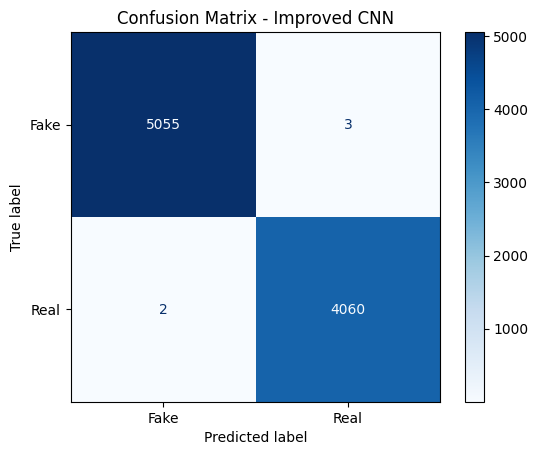

In [ ]:
#Classification Report & Confusion Matrix
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Classification Report
print("\nClassification Report\n")
print(classification_report(y_test, y_pred))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Fake", "Real"]
)

plt.figure(figsize=(6,6))
disp.plot(cmap="Blues")
plt.title("Confusion Matrix - Improved CNN")

plt.savefig(
    "/content/drive/MyDrive/VocaTrust/Phase2/evaluation/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

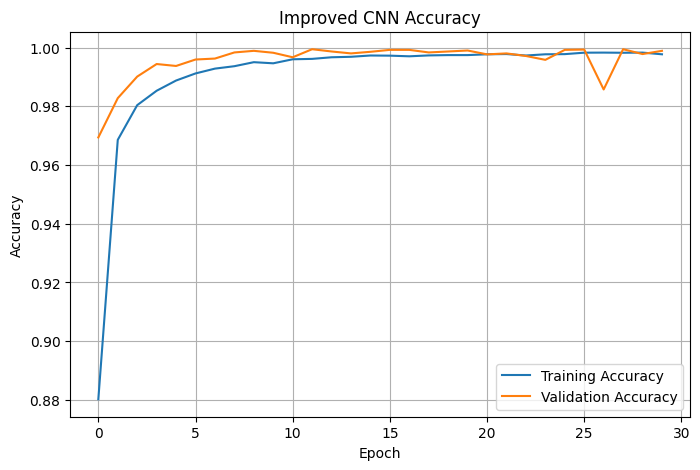

In [ ]:
#Accuracy Graph
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(history_phase2.history['accuracy'], label='Training Accuracy')
plt.plot(history_phase2.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Improved CNN Accuracy")
plt.legend()
plt.grid(True)

plt.savefig(
    "/content/drive/MyDrive/VocaTrust/Phase2/evaluation/accuracy_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

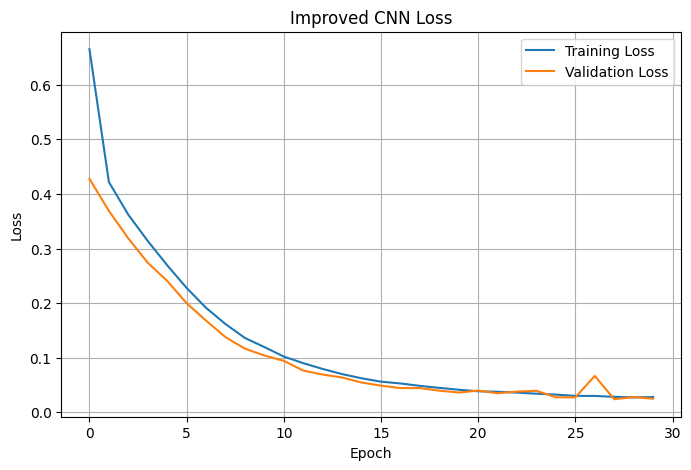

In [ ]:
#Loss Graph
plt.figure(figsize=(8,5))

plt.plot(history_phase2.history['loss'], label='Training Loss')
plt.plot(history_phase2.history['val_loss'], label='Validation Loss')

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Improved CNN Loss")
plt.legend()
plt.grid(True)

plt.savefig(
    "/content/drive/MyDrive/VocaTrust/Phase2/evaluation/loss_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
#Save Evaluation Results
with open(
    "/content/drive/MyDrive/VocaTrust/Phase2/evaluation/results.txt",
    "w"
) as f:

    f.write(f"Test Accuracy : {test_accuracy:.4f}\n")
    f.write(f"Test Loss     : {test_loss:.4f}\n\n")

    f.write("Classification Report\n")
    f.write(classification_report(y_test, y_pred))

print("✅ Evaluation results saved successfully.")

✅ Evaluation results saved successfully.


In [ ]:
# @title
import os
from sklearn.model_selection import train_test_split

real_path = "/content/drive/MyDrive/VocaTrust/clean_data/real"

real_files = sorted(os.listdir(real_path))

train_files, test_files = train_test_split(
    real_files,
    test_size=0.2,
    random_state=42
)

# Extract speaker IDs (first part of filename)
train_speakers = {f.split("-")[0] for f in train_files}
test_speakers = {f.split("-")[0] for f in test_files}

common_speakers = train_speakers.intersection(test_speakers)

print("Training speakers :", len(train_speakers))
print("Testing speakers  :", len(test_speakers))
print("Common speakers   :", len(common_speakers))

Training speakers : 251
Testing speakers  : 247
Common speakers   : 247


In [ ]:
# Phase 2 – Step 2
## Enhanced Feature Extraction using MFCC + Delta + Delta-Delta


In [ ]:
import os

real_path = "/content/drive/MyDrive/VocaTrust/clean_data/real"
fake_path = "/content/drive/MyDrive/VocaTrust/clean_data/fake"

real_files = [
    os.path.join(real_path, f)
    for f in os.listdir(real_path)
    if f.endswith(".wav")
]

fake_files = [
    os.path.join(fake_path, f)
    for f in os.listdir(fake_path)
    if f.endswith(".wav")
]

print("Real files:", len(real_files))
print("Fake files:", len(fake_files))

Real files: 20219
Fake files: 25380


In [ ]:
import librosa
import numpy as np

def extract_features(file_path):
    try:
        y, sr = librosa.load(file_path, sr=16000)

        # Skip empty or very short audio
        if len(y) < 2048:
            return None

        # Faster MFCC computation
        mfcc = librosa.feature.mfcc(
            y=y,
            sr=sr,
            n_mfcc=13,
            n_fft=1024,
            hop_length=512
        )

        delta = librosa.feature.delta(mfcc)
        delta2 = librosa.feature.delta(mfcc, order=2)

        features = np.vstack((mfcc, delta, delta2))

        max_len = 100

        if features.shape[1] < max_len:
            features = np.pad(
                features,
                ((0, 0), (0, max_len - features.shape[1])),
                mode="constant"
            )
        else:
            features = features[:, :max_len]

        return features.astype(np.float32)

    except Exception:
        return None

In [ ]:
# @title
sample = extract_features(real_files[0])

print(sample.shape)

(39, 100)


In [ ]:
# @title

print(len(real_files))
print(len(fake_files))
print(len(real_files) + len(fake_files))

20219
25380
45599


In [ ]:
X = []
y = []

print("Processing Real Audio...")

for i, file in enumerate(real_files):
    feature = extract_features(file)

    if feature is not None:
        X.append(feature)
        y.append(1)

    if (i + 1) % 500 == 0:
        print(f"Processed {i + 1}/{len(real_files)} real files")

print("Processing Fake Audio...")

for i, file in enumerate(fake_files):
    feature = extract_features(file)

    if feature is not None:
        X.append(feature)
        y.append(0)

    if (i + 1) % 500 == 0:
        print(f"Processed {i + 1}/{len(fake_files)} fake files")

X = np.array(X, dtype=np.float32)
y = np.array(y)

Processing Real Audio...
Processed 500/20219 real files
Processed 1000/20219 real files
Processed 1500/20219 real files
Processed 2000/20219 real files
Processed 2500/20219 real files
Processed 3000/20219 real files
Processed 3500/20219 real files
Processed 4000/20219 real files
Processed 4500/20219 real files
Processed 5000/20219 real files
Processed 5500/20219 real files
Processed 6000/20219 real files
Processed 6500/20219 real files
Processed 7000/20219 real files
Processed 7500/20219 real files
Processed 8000/20219 real files
Processed 8500/20219 real files
Processed 9000/20219 real files
Processed 9500/20219 real files
Processed 10000/20219 real files
Processed 10500/20219 real files
Processed 11000/20219 real files
Processed 11500/20219 real files
Processed 12000/20219 real files
Processed 12500/20219 real files
Processed 13000/20219 real files
Processed 13500/20219 real files
Processed 14000/20219 real files
Processed 14500/20219 real files
Processed 15000/20219 real files
Proce

In [ ]:
print(len(X))
print(len(y))

45599
45599


In [ ]:
try:
    print(X.shape)
except Exception as e:
    print(e)

(45599, 39, 100)


In [ ]:
#saved extracted features
import os
import numpy as np

save_dir = "/content/drive/MyDrive/VocaTrust/Phase2/Step2_EnhancedFeatures"
os.makedirs(save_dir, exist_ok=True)

np.save(os.path.join(save_dir, "X_step2.npy"), X)
np.save(os.path.join(save_dir, "y_step2.npy"), y)

print("Features saved successfully!")

Features saved successfully!


In [ ]:
#Train Enhanced CNN

In [ ]:
#Load the saved features
import numpy as np

X = np.load("/content/drive/MyDrive/VocaTrust/Phase2/Step2_EnhancedFeatures/X_step2.npy")
y = np.load("/content/drive/MyDrive/VocaTrust/Phase2/Step2_EnhancedFeatures/y_step2.npy")

print("X:", X.shape)
print("y:", y.shape)

X: (45599, 39, 100)
y: (45599,)


In [ ]:
#Train-Test Split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing :", X_test.shape)

Training: (36479, 39, 100)
Testing : (9120, 39, 100)


In [ ]:
#Add Channel Dimension ,CNN expects 4D input.

X_train = X_train[..., np.newaxis]
X_test = X_test[..., np.newaxis]

print(X_train.shape)
print(X_test.shape)

(36479, 39, 100, 1)
(9120, 39, 100, 1)


In [ ]:
#Import Libraries
import tensorflow as tf

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    BatchNormalization,
    Dense,
    Dropout,
    Flatten
)

from tensorflow.keras.regularizers import l2

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    CSVLogger
)

In [ ]:
#Build Improved CNN , This is an upgraded architecture compared to Step 1.

model = Sequential()

model.add(
    Conv2D(
        32,
        (3,3),
        activation="relu",
        padding="same",
        kernel_regularizer=l2(0.001),
        input_shape=(39,100,1)
    )
)

model.add(BatchNormalization())
model.add(MaxPooling2D((2,2)))
model.add(Dropout(0.30))

model.add(
    Conv2D(
        64,
        (3,3),
        activation="relu",
        padding="same",
        kernel_regularizer=l2(0.001)
    )
)

model.add(BatchNormalization())
model.add(MaxPooling2D((2,2)))
model.add(Dropout(0.30))

model.add(
    Conv2D(
        128,
        (3,3),
        activation="relu",
        padding="same",
        kernel_regularizer=l2(0.001)
    )
)

model.add(BatchNormalization())
model.add(MaxPooling2D((2,2)))
model.add(Dropout(0.40))

model.add(Flatten())

model.add(
    Dense(
        256,
        activation="relu",
        kernel_regularizer=l2(0.001)
    )
)

model.add(Dropout(0.50))

model.add(Dense(1, activation="sigmoid"))

model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 39, 100, 32)    │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 39, 100, 32)    │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 19, 50, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 19, 50, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 19, 50, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 19, 50, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 9, 25, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 9, 25, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 9, 25, 128)     │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 9, 25, 128)     │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 12, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 12, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6144)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     1,573,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,666,945 (6.36 MB)

 Trainable params: 1,666,497 (6.36 MB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
#Compile
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
#Callbacks
checkpoint = ModelCheckpoint(
    "/content/drive/MyDrive/VocaTrust/Phase2/Step2_EnhancedFeatures/best_model.keras",
    monitor="val_accuracy",
    save_best_only=True,
    mode="max"
)

earlystop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

logger = CSVLogger(
    "/content/drive/MyDrive/VocaTrust/Phase2/Step2_EnhancedFeatures/training_log.csv"
)

In [ ]:
#Train
history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=30,
    batch_size=32,
    callbacks=[
        checkpoint,
        earlystop,
        logger
    ]
)

Epoch 1/30
912/912 ━━━━━━━━━━━━━━━━━━━━ 26s 17ms/step - accuracy: 0.9559 - loss: 0.4899 - val_accuracy: 0.9722 - val_loss: 0.2998
Epoch 2/30
912/912 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.9861 - loss: 0.2301 - val_accuracy: 0.9927 - val_loss: 0.1890
Epoch 3/30
912/912 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.9896 - loss: 0.1833 - val_accuracy: 0.9964 - val_loss: 0.1654
Epoch 4/30
912/912 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.9902 - loss: 0.1641 - val_accuracy: 0.9827 - val_loss: 0.1754
Epoch 5/30
912/912 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.9912 - loss: 0.1479 - val_accuracy: 0.9345 - val_loss: 0.3239
Epoch 6/30
912/912 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.9909 - loss: 0.1398 - val_accuracy: 0.9936 - val_loss: 0.1382
Epoch 7/30
912/912 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.9917 - loss: 0.1304 - val_accuracy: 0.9882 - val_loss: 0.1216
Epoch 8/30
912/912 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.9924 - loss: 0.1144 - val_accuracy:

In [ ]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=1)

print(f"Test Accuracy : {test_accuracy*100:.4f}%")
print(f"Test Loss     : {test_loss:.4f}")

285/285 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.9978 - loss: 0.0850
Test Accuracy : 99.7807%
Test Loss     : 0.0850


285/285 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      5076
           1       1.00      1.00      1.00      4044

    accuracy                           1.00      9120
   macro avg       1.00      1.00      1.00      9120
weighted avg       1.00      1.00      1.00      9120



<Figure size 600x600 with 0 Axes>

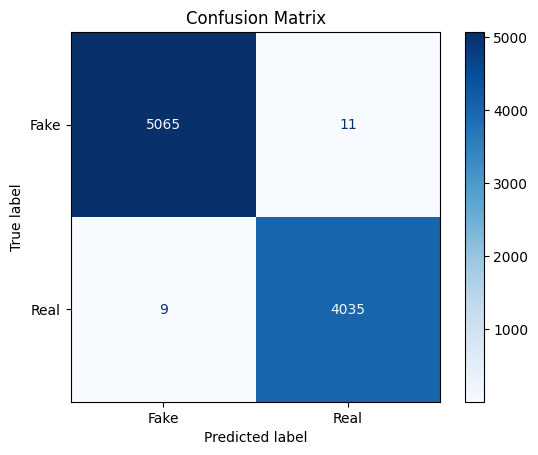

In [ ]:
#Evaluate the model completely


from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

y_pred = (model.predict(X_test) > 0.5).astype(int)

print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Fake", "Real"]
)

plt.figure(figsize=(6,6))
disp.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.savefig(
    os.path.join(save_dir, "Confusion_Matrix.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

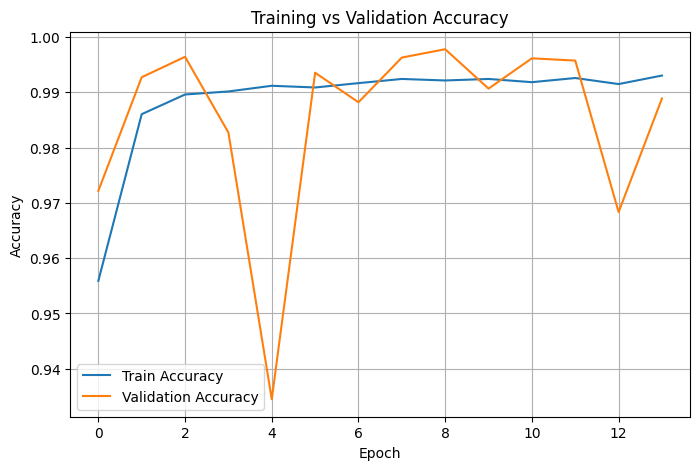

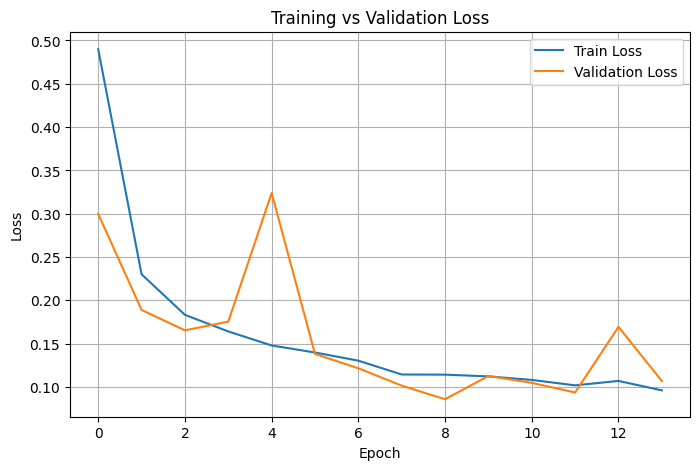

In [ ]:
#Plot the training curves
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.savefig(
    os.path.join(save_dir, "Accuracy_Curve.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.figure(figsize=(8,5))
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.savefig(
    os.path.join(save_dir, "Loss_Curve.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
#Save the final trained model
import os

save_dir = "/content/drive/MyDrive/VocaTrust/Phase2/Step2_EnhancedFeatures"
os.makedirs(save_dir, exist_ok=True)

model.save(os.path.join(save_dir, "Step2_Final_Model.keras"))

print("✅ Final model saved successfully!")

✅ Final model saved successfully!


In [ ]:
#Save the training history
import pandas as pd

history_df = pd.DataFrame(history.history)

history_df.to_csv(
    os.path.join(save_dir, "Step2_Training_History.csv"),
    index=False
)

print("✅ Training history saved!")

✅ Training history saved!


In [ ]:
#Save the test results
results = {
    "Test Accuracy": test_accuracy,
    "Test Loss": test_loss
}

pd.DataFrame([results]).to_csv(
    os.path.join(save_dir, "Step2_Test_Results.csv"),
    index=False
)

print("✅ Test results saved!")

✅ Test results saved!


In [ ]:
#Save the model architecture
with open(os.path.join(save_dir, "Step2_Model_Summary.txt"), "w") as f:
    model.summary(print_fn=lambda x: f.write(x + "\n"))

print("✅ Model summary saved!")

✅ Model summary saved!


In [ ]:
#Save the Classification Report
from sklearn.metrics import classification_report
import pandas as pd

report = classification_report(
    y_test,
    y_pred,
    output_dict=True
)

report_df = pd.DataFrame(report).transpose()

report_df.to_csv(
    os.path.join(save_dir, "Classification_Report.csv")
)

print(report_df)

              precision    recall  f1-score      support
0              0.998226  0.997833  0.998030  5076.000000
1              0.997281  0.997774  0.997528  4044.000000
accuracy       0.997807  0.997807  0.997807     0.997807
macro avg      0.997754  0.997804  0.997779  9120.000000
weighted avg   0.997807  0.997807  0.997807  9120.000000


In [ ]:
#Save the Predictions
prediction_df = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred.flatten()
})

prediction_df.to_csv(
    os.path.join(save_dir, "Predictions.csv"),
    index=False
)

print("Predictions saved.")

Predictions saved.


In [ ]:
#Save Final Evaluation Results
results = pd.DataFrame({
    "Metric": [
        "Test Accuracy",
        "Test Loss"
    ],
    "Value": [
        test_accuracy,
        test_loss
    ]
})

results.to_csv(
    os.path.join(save_dir, "Final_Evaluation.csv"),
    index=False
)

print(results)

          Metric     Value
0  Test Accuracy  0.997807
1      Test Loss  0.085035


In [ ]:
#Load the model:

from tensorflow.keras.models import load_model

model = load_model(
    "/content/drive/MyDrive/VocaTrust/Phase2/Step2_EnhancedFeatures/Step2_Final_Model.keras"
)

print("✅ Model loaded successfully!")

In [ ]:
#LOAD FEATURES
import numpy as np

X = np.load("/content/drive/MyDrive/VocaTrust/Phase2/Step2_EnhancedFeatures/X_step2.npy")
y = np.load("/content/drive/MyDrive/VocaTrust/Phase2/Step2_EnhancedFeatures/y_step2.npy")

In [ ]:
#Explainable AI method

In [ ]:
import tensorflow as tf
import numpy as np
import librosa
import matplotlib.pyplot as plt

from tensorflow.keras.models import load_model

In [ ]:
#Load the model:
MODEL_PATH = "/content/drive/MyDrive/VocaTrust/Phase2/Step2_EnhancedFeatures/Step2_Final_Model.keras"

model = load_model(MODEL_PATH)

print("✅ VocaTrust model loaded.")

✅ VocaTrust model loaded.


In [ ]:
#Feature Extraction
def extract_features(audio_path):

    y, sr = librosa.load(audio_path, sr=16000)

    mfcc = librosa.feature.mfcc(
        y=y,
        sr=sr,
        n_mfcc=13,
        n_fft=1024,
        hop_length=512
    )

    delta = librosa.feature.delta(mfcc)

    delta2 = librosa.feature.delta(
        mfcc,
        order=2
    )

    features = np.vstack((mfcc, delta, delta2))

    max_len = 100

    if features.shape[1] < max_len:

        pad = max_len - features.shape[1]

        features = np.pad(
            features,
            ((0,0),(0,pad)),
            mode="constant"
        )

    else:

        features = features[:, :100]

    return features.astype(np.float32)

In [ ]:
#Choose one sample
audio_path = real_files[50]

# Try fake_files[50] later

print(audio_path)

/content/drive/MyDrive/VocaTrust/clean_data/real/374-180298-0059.wav


In [ ]:
#Prediction function.

def predict_voice(audio_path):

    features = extract_features(audio_path)

    X = np.expand_dims(features, axis=0)
    X = np.expand_dims(X, axis=-1)

    probability_real = float(model.predict(X, verbose=0)[0][0])

    if probability_real >= 0.5:
        label = "REAL"
        confidence = probability_real
        integrity_score = probability_real * 100
    else:
        label = "FAKE"
        confidence = 1 - probability_real
        integrity_score = (1 - probability_real) * 100

    integrity_score = round(integrity_score, 2)
    confidence = round(confidence * 100, 2)

    return {
        "label": label,
        "confidence": confidence,
        "integrity_score": integrity_score,
        "probability_real": probability_real
    }

In [ ]:
#Run prediction.
result = predict_voice(audio_path)

result

{'label': 'REAL',
 'confidence': 99.84,
 'integrity_score': 99.84,
 'probability_real': 0.9983990788459778}

In [ ]:
#Voice Trust Meter + Professional
 #Risk Classification
def get_risk_level(score):

    if score >= 80:
        return "🟢 GENUINE"

    elif score >= 50:
        return "🟡 SUSPICIOUS"

    else:
        return "🔴 HIGH RISK"

In [ ]:
#Voice Trust Meter
def trust_meter(score):

    total_blocks = 30

    filled = int((score / 100) * total_blocks)

    empty = total_blocks - filled

    meter = "█" * filled + "░" * empty

    print("\nVoice Trust Meter")
    print("0", meter, "100")
    print(f"Integrity Score : {score:.2f}%")

In [ ]:
#AI Report
def generate_report(result):

    score = result["integrity_score"]

    risk = get_risk_level(score)

    print("\n")
    print("="*60)
    print("               VOCATRUST AI REPORT")
    print("="*60)

    print(f"Prediction           : {result['label']}")
    print(f"Confidence           : {result['confidence']:.2f}%")
    print(f"Voice Integrity      : {score:.2f}%")
    print(f"Risk Level           : {risk}")

    trust_meter(score)

    print("="*60)

In [ ]:
#Display the Report
result = predict_voice(audio_path)

generate_report(result)



               VOCATRUST AI REPORT
Prediction           : REAL
Confidence           : 99.84%
Voice Integrity      : 99.84%
Risk Level           : 🟢 GENUINE

Voice Trust Meter
0 █████████████████████████████░ 100
Integrity Score : 99.84%


In [ ]:
# @title
#Grad-CAM Explainable AI
#Find the Last Convolution Layer



for layer in model.layers:
    print(layer.name, layer.output.shape)

conv2d (None, 39, 100, 32)
batch_normalization (None, 39, 100, 32)
max_pooling2d (None, 19, 50, 32)
dropout (None, 19, 50, 32)
conv2d_1 (None, 19, 50, 64)
batch_normalization_1 (None, 19, 50, 64)
max_pooling2d_1 (None, 9, 25, 64)
dropout_1 (None, 9, 25, 64)
conv2d_2 (None, 9, 25, 128)
batch_normalization_2 (None, 9, 25, 128)
max_pooling2d_2 (None, 4, 12, 128)
dropout_2 (None, 4, 12, 128)
flatten (None, 6144)
dense (None, 256)
dropout_3 (None, 256)
dense_1 (None, 1)


In [ ]:
for i, layer in enumerate(model.layers):
    print(i, layer.name, layer.__class__.__name__)

0 conv2d Conv2D
1 batch_normalization BatchNormalization
2 max_pooling2d MaxPooling2D
3 dropout Dropout
4 conv2d_1 Conv2D
5 batch_normalization_1 BatchNormalization
6 max_pooling2d_1 MaxPooling2D
7 dropout_1 Dropout
8 conv2d_2 Conv2D
9 batch_normalization_2 BatchNormalization
10 max_pooling2d_2 MaxPooling2D
11 dropout_2 Dropout
12 flatten Flatten
13 dense Dense
14 dropout_3 Dropout
15 dense_1 Dense


In [ ]:
#Explainable AI using Score-CAM

In [ ]:
#xplainable AI using Score-CAM
import tensorflow as tf

# Feature extractor up to the last convolution layer
feature_extractor = tf.keras.Model(
    inputs=model.inputs,
    outputs=model.get_layer("conv2d_2").output
)

print("Feature Extractor Created")


Feature Extractor Created


In [ ]:
feature_extractor.save(
    "/content/drive/MyDrive/VocaTrust/Phase2/Explainable_AI/Feature_Extractor.keras"
)

In [ ]:
#Extract Feature Maps
feature_maps = feature_extractor.predict(sample)

print("Feature Map Shape:", feature_maps.shape)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
Feature Map Shape: (1, 9, 25, 128)


In [ ]:
#Create the Classifier Model
classifier = tf.keras.Sequential([
    model.get_layer("batch_normalization_2"),
    model.get_layer("max_pooling2d_2"),
    model.get_layer("dropout_2"),
    model.get_layer("flatten"),
    model.get_layer("dense"),
    model.get_layer("dropout_3"),
    model.get_layer("dense_1")
])

print("Classifier Created")

Classifier Created


In [ ]:
classifier.save(
    "/content/drive/MyDrive/VocaTrust/Phase2/Explainable_AI/Classifier.keras"
)

In [ ]:
#Test the Classifier
prediction = classifier(feature_maps, training=False)

print(prediction.numpy())

[[0.41149643]]


In [ ]:
#score-CAM weights
import numpy as np
import cv2
from tqdm import tqdm

feature_maps_single = feature_maps[0]

weights = []

for i in tqdm(range(feature_maps_single.shape[-1])):

    fmap = feature_maps_single[:, :, i]

    # Normalize feature map
    fmap = fmap - np.min(fmap)

    if np.max(fmap) > 0:
        fmap = fmap / np.max(fmap)

    # Resize to MFCC size
    mask = cv2.resize(fmap, (100, 39))

    mask = np.expand_dims(mask, axis=-1)

    masked_sample = sample[0] * mask
    masked_sample = np.expand_dims(masked_sample, axis=0)

    masked_features = feature_extractor.predict(
        masked_sample,
        verbose=0
    )

    score = classifier(
        masked_features,
        training=False
    ).numpy()[0][0]

    weights.append(score)

weights = np.array(weights)

print("Weights Shape :", weights.shape)
print("Max Weight    :", weights.max())
print("Min Weight    :", weights.min())

100%|██████████| 128/128 [00:11<00:00, 11.03it/s]

Weights Shape : (128,)
Max Weight    : 0.078213505
Min Weight    : 4.5646048e-05


In [ ]:
#Score-CAM weights saved
import os
import numpy as np

save_dir = "/content/drive/MyDrive/VocaTrust/Phase2/Explainable_AI"
os.makedirs(save_dir, exist_ok=True)

np.save(
    os.path.join(save_dir, "scorecam_weights.npy"),
    weights
)

print("✅ Score-CAM weights saved successfully!")

✅ Score-CAM weights saved successfully!


In [ ]:
#Generate the Heatmap
heatmap = np.zeros(feature_maps_single.shape[:2], dtype=np.float32)

for i in range(feature_maps_single.shape[-1]):
    heatmap += weights[i] * feature_maps_single[:, :, i]

# Apply ReLU
heatmap = np.maximum(heatmap, 0)

# Normalize to [0,1]
heatmap /= (heatmap.max() + 1e-10)

print("Heatmap Shape :", heatmap.shape)
print("Heatmap Min   :", heatmap.min())
print("Heatmap Max   :", heatmap.max())

Heatmap Shape : (9, 25)
Heatmap Min   : 0.09862265
Heatmap Max   : 1.0


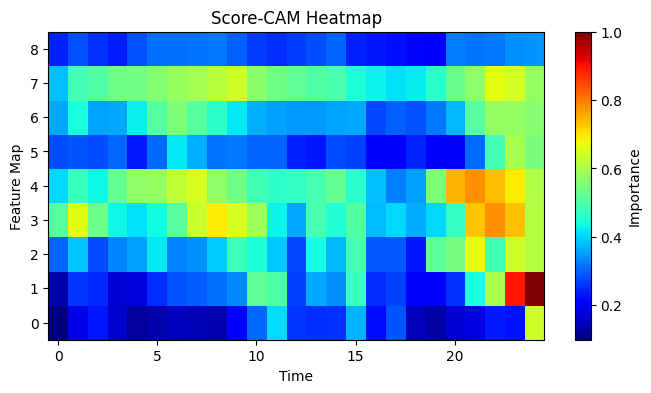

In [ ]:
#Display the Heatmap
import matplotlib.pyplot as plt

plt.figure(figsize=(8,4))

plt.imshow(
    heatmap,
    cmap="jet",
    aspect="auto",
    origin="lower"
)

plt.colorbar(label="Importance")

plt.title("Score-CAM Heatmap")

plt.xlabel("Time")

plt.ylabel("Feature Map")

plt.show()

In [ ]:
#Save Everything
import os
import numpy as np
import matplotlib.pyplot as plt

save_dir = "/content/drive/MyDrive/VocaTrust/Phase2/Explainable_AI"

# Save heatmap array
np.save(
    os.path.join(save_dir, "scorecam_heatmap.npy"),
    heatmap
)

# Save image
plt.figure(figsize=(8,4))
plt.imshow(
    heatmap,
    cmap="jet",
    aspect="auto",
    origin="lower"
)
plt.colorbar(label="Importance")
plt.title("Score-CAM Heatmap")
plt.xlabel("Time")
plt.ylabel("Feature Map")

plt.savefig(
    os.path.join(save_dir, "ScoreCAM_Heatmap.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.close()

print("✅ Heatmap and image saved successfully!")

✅ Heatmap and image saved successfully!


In [ ]:
import numpy as np

np.save(
    "/content/drive/MyDrive/VocaTrust/Phase2/Explainable_AI/feature_maps.npy",
    feature_maps
)

In [ ]:
#save the numerical heatmap statistics
import pandas as pd
import os

save_dir = "/content/drive/MyDrive/VocaTrust/Phase2/Explainable_AI"

stats = pd.DataFrame({
    "Metric": [
        "Heatmap Shape",
        "Minimum",
        "Maximum",
        "Mean",
        "Standard Deviation"
    ],
    "Value": [
        str(heatmap.shape),
        float(heatmap.min()),
        float(heatmap.max()),
        float(heatmap.mean()),
        float(heatmap.std())
    ]
})

stats.to_csv(
    os.path.join(save_dir, "Heatmap_Statistics.csv"),
    index=False
)

print("✅ Heatmap statistics saved.")

✅ Heatmap statistics saved.


In [ ]:
#Explainability Visualization

In [ ]:
#Resize the Heatmap
import cv2
import numpy as np

# Resize from (9,25) → (39,100)
heatmap_resized = cv2.resize(
    heatmap,
    (100, 39),
    interpolation=cv2.INTER_CUBIC
)

print("Original Heatmap :", heatmap.shape)
print("Resized Heatmap  :", heatmap_resized.shape)

Original Heatmap : (9, 25)
Resized Heatmap  : (39, 100)


In [ ]:
# @title
#SAVE
import os
import numpy as np

save_dir = "/content/drive/MyDrive/VocaTrust/Phase2/Explainable_AI"

np.save(
    os.path.join(save_dir, "scorecam_heatmap_resized.npy"),
    heatmap_resized
)

print("✅ Resized heatmap saved.")

✅ Resized heatmap saved.


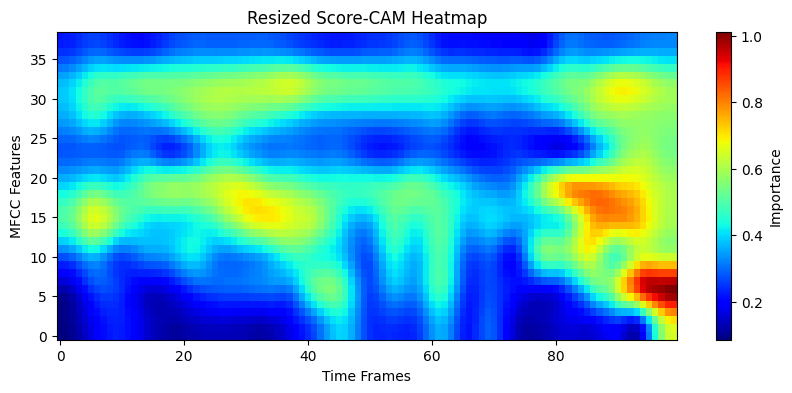

In [ ]:
#Display the Resized Heatmap
import matplotlib.pyplot as plt

plt.figure(figsize=(10,4))

plt.imshow(
    heatmap_resized,
    cmap="jet",
    origin="lower",
    aspect="auto"
)

plt.colorbar(label="Importance")

plt.title("Resized Score-CAM Heatmap")

plt.xlabel("Time Frames")

plt.ylabel("MFCC Features")

plt.show()

In [ ]:
# @title
#SAVE
plt.figure(figsize=(10,4))

plt.imshow(
    heatmap_resized,
    cmap="jet",
    origin="lower",
    aspect="auto"
)

plt.colorbar(label="Importance")
plt.title("Resized Score-CAM Heatmap")

plt.savefig(
    os.path.join(
        save_dir,
        "ScoreCAM_Heatmap_Resized.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.close()

print("✅ Resized heatmap image saved.")

✅ Resized heatmap image saved.


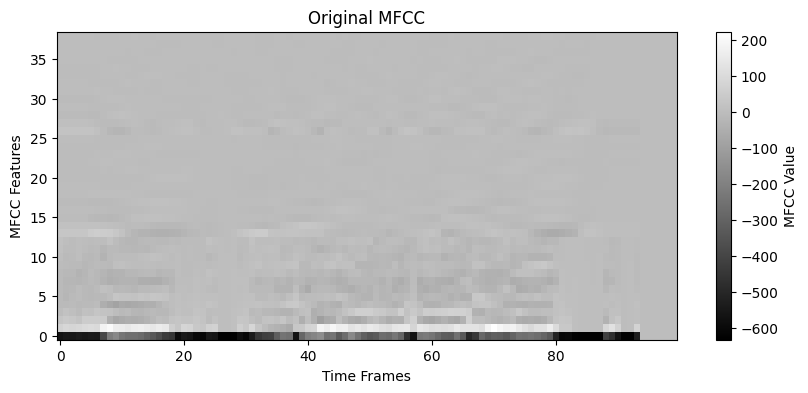

In [ ]:
#DISPLAY ORIGINAL MFCC
import matplotlib.pyplot as plt

plt.figure(figsize=(10,4))

plt.imshow(
    mfcc,
    aspect="auto",
    origin="lower",
    cmap="gray"
)

plt.colorbar(label="MFCC Value")

plt.title("Original MFCC")

plt.xlabel("Time Frames")
plt.ylabel("MFCC Features")

plt.show()

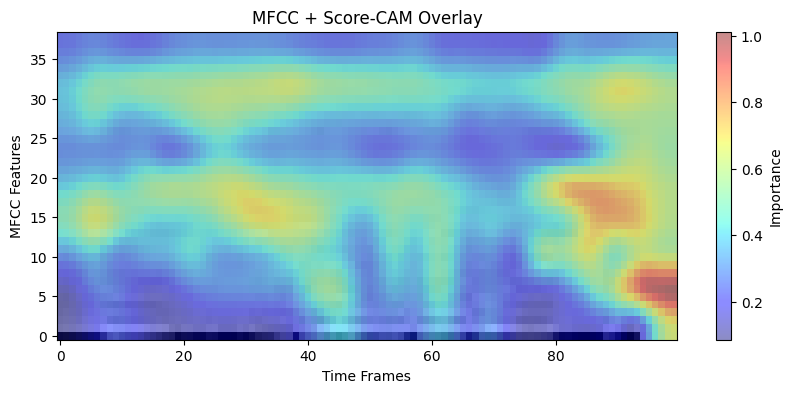

In [ ]:
#Overlay Heatmap
plt.figure(figsize=(10,4))

# Original MFCC
plt.imshow(
    mfcc,
    cmap="gray",
    origin="lower",
    aspect="auto"
)

# Score-CAM Overlay
plt.imshow(
    heatmap_resized,
    cmap="jet",
    alpha=0.45,
    origin="lower",
    aspect="auto"
)

plt.colorbar(label="Importance")

plt.title("MFCC + Score-CAM Overlay")

plt.xlabel("Time Frames")
plt.ylabel("MFCC Features")

plt.show()

In [ ]:
# @title
#SAVE
import os

save_dir = "/content/drive/MyDrive/VocaTrust/Phase2/Explainable_AI"

plt.figure(figsize=(10,4))

plt.imshow(
    mfcc,
    cmap="gray",
    origin="lower",
    aspect="auto"
)

plt.imshow(
    heatmap_resized,
    cmap="jet",
    alpha=0.45,
    origin="lower",
    aspect="auto"
)

plt.colorbar(label="Importance")

plt.title("MFCC + Score-CAM Overlay")

plt.savefig(
    os.path.join(save_dir, "MFCC_ScoreCAM_Overlay.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.close()

print("✅ Overlay saved successfully!")

✅ Overlay saved successfully!


In [ ]:
#Calculate Statistics
import numpy as np
import pandas as pd

peak_attention = float(np.max(heatmap_resized))
mean_attention = float(np.mean(heatmap_resized))
std_attention = float(np.std(heatmap_resized))

# Percentage of pixels with attention > 0.5
attention_threshold = 0.5
attention_coverage = (
    np.sum(heatmap_resized > attention_threshold)
    / heatmap_resized.size
) * 100

# Time frame with maximum attention
max_index = np.unravel_index(
    np.argmax(heatmap_resized),
    heatmap_resized.shape
)

important_feature = int(max_index[0])
important_frame = int(max_index[1])

print("Peak Attention      :", peak_attention)
print("Mean Attention      :", mean_attention)
print("Std Attention       :", std_attention)
print("Attention Coverage  :", attention_coverage, "%")
print("Most Important MFCC :", important_feature)
print("Most Important Time :", important_frame)

Peak Attention      : 1.011371374130249
Mean Attention      : 0.4001511335372925
Std Attention       : 0.1548771858215332
Attention Coverage  : 25.846153846153847 %
Most Important MFCC : 6
Most Important Time : 99


In [ ]:
# @title
#Save Statistics
import os

stats = pd.DataFrame({
    "Metric": [
        "Peak Attention",
        "Mean Attention",
        "Std Attention",
        "Attention Coverage (%)",
        "Most Important MFCC",
        "Most Important Time Frame"
    ],
    "Value": [
        peak_attention,
        mean_attention,
        std_attention,
        attention_coverage,
        important_feature,
        important_frame
    ]
})

save_dir = "/content/drive/MyDrive/VocaTrust/Phase2/Explainable_AI"

stats.to_csv(
    os.path.join(save_dir, "Attention_Statistics.csv"),
    index=False
)

print("✅ Attention statistics saved.")

✅ Attention statistics saved.


In [ ]:
#Generate AI Interpretation



prediction_probability = float(prediction.numpy()[0][0])

# Binary prediction
if prediction_probability >= 0.5:
    prediction_label = "REAL"
else:
    prediction_label = "FAKE"

# Confidence
confidence = max(
    prediction_probability,
    1 - prediction_probability
) * 100

# Voice Integrity Score
voice_integrity = prediction_probability * 100

# Risk Level
if voice_integrity >= 80:
    risk = "LOW RISK (Likely Genuine)"
elif voice_integrity >= 50:
    risk = "MEDIUM RISK (Suspicious)"
else:
    risk = "HIGH RISK (Likely AI Generated)"

# Automatic interpretation
interpretation = (
    f"The model focused mainly on MFCC feature "
    f"{important_feature} around time frame "
    f"{important_frame}. "
    f"Attention coverage was {attention_coverage:.2f}% "
    f"with a peak activation of {peak_attention:.2f}. "
    f"This indicates that these acoustic regions had "
    f"the strongest influence on the prediction."
)

print(interpretation)

The model focused mainly on MFCC feature 6 around time frame 99. Attention coverage was 25.85% with a peak activation of 1.01. This indicates that these acoustic regions had the strongest influence on the prediction.


In [ ]:
#CREATE REPORT
report = {
    "Prediction": prediction_label,
    "Confidence (%)": round(confidence,2),
    "Voice Integrity Score": round(voice_integrity,2),
    "Risk Level": risk,
    "Peak Attention": round(peak_attention,4),
    "Mean Attention": round(mean_attention,4),
    "Attention Coverage (%)": round(attention_coverage,2),
    "Most Important MFCC": important_feature,
    "Most Important Time Frame": important_frame,
    "Interpretation": interpretation
}

In [ ]:
# @title
#Save Report
import pandas as pd
import os

save_dir="/content/drive/MyDrive/VocaTrust/Phase2/Explainable_AI"

report_df = pd.DataFrame(
    report.items(),
    columns=["Metric","Value"]
)

report_df.to_csv(
    os.path.join(save_dir,"VocaTrust_AI_Report.csv"),
    index=False
)

print("✅ AI Report saved successfully.")

✅ AI Report saved successfully.


In [ ]:
print("="*55)
print("          VOCATRUST AI REPORT")
print("="*55)

for key,value in report.items():
    print(f"{key:<28}: {value}")

print("="*55)

          VOCATRUST AI REPORT
Prediction                  : FAKE
Confidence (%)              : 58.85
Voice Integrity Score       : 41.15
Risk Level                  : HIGH RISK (Likely AI Generated)
Peak Attention              : 1.0114
Mean Attention              : 0.4002
Attention Coverage (%)      : 25.85
Most Important MFCC         : 6
Most Important Time Frame   : 99
Interpretation              : The model focused mainly on MFCC feature 6 around time frame 99. Attention coverage was 25.85% with a peak activation of 1.01. This indicates that these acoustic regions had the strongest influence on the prediction.


In [ ]:
#TESTING EXPLAINABLE AI

In [ ]:
#Select a REAL audio
import os
import random

real_path = "/content/drive/MyDrive/VocaTrust/clean_data/real"

real_files = sorted([
    os.path.join(real_path, f)
    for f in os.listdir(real_path)
    if f.endswith(".wav")
])

real_audio = random.choice(real_files)

print("Selected REAL audio:")
print(real_audio)

Selected REAL audio:
/content/drive/MyDrive/VocaTrust/clean_data/real/4640-19187-0022.wav


In [ ]:
#Select a FAKE audio
fake_path = "/content/drive/MyDrive/VocaTrust/clean_data/fake"

fake_files = sorted([
    os.path.join(fake_path, f)
    for f in os.listdir(fake_path)
    if f.endswith(".wav")
])

fake_audio = random.choice(fake_files)

print("Selected FAKE audio:")
print(fake_audio)

Selected FAKE audio:
/content/drive/MyDrive/VocaTrust/clean_data/fake/LA_T_2909374.wav


In [ ]:
#Verify CNN prediction

print("REAL AUDIO")
print(predict_voice(real_audio))

print("\n---------------------------------\n")

print("FAKE AUDIO")
print(predict_voice(fake_audio))

REAL AUDIO
{'label': 'REAL', 'confidence': 99.99, 'integrity_score': 99.99, 'probability_real': 0.999946117401123}

---------------------------------

FAKE AUDIO
{'label': 'FAKE', 'confidence': 100.0, 'integrity_score': 100.0, 'probability_real': 3.2624115214874294e-11}


In [ ]:
features = extract_features(real_audio)

X_input = np.expand_dims(features, axis=0)
X_input = np.expand_dims(X_input, axis=-1)

print(X_input.shape)

(1, 39, 100, 1)


In [ ]:
feature_maps = feature_extractor.predict(X_input, verbose=0)

print("Feature Maps Shape:", feature_maps.shape)

Feature Maps Shape: (1, 9, 25, 128)


In [ ]:
# Use the current audio as the sample for Score-CAM
sample = X_input

# Score-CAM Weights
import numpy as np
import cv2
from tqdm import tqdm

feature_maps_single = feature_maps[0]

weights = []

for i in tqdm(range(feature_maps_single.shape[-1])):

    fmap = feature_maps_single[:, :, i]

    # Normalize feature map
    fmap = fmap - np.min(fmap)

    if np.max(fmap) > 0:
        fmap = fmap / np.max(fmap)

    # Resize to MFCC size
    mask = cv2.resize(fmap, (100, 39))

    mask = np.expand_dims(mask, axis=-1)

    # Apply mask to current audio sample
    masked_sample = sample[0] * mask
    masked_sample = np.expand_dims(masked_sample, axis=0)

    # Generate masked feature maps
    masked_features = feature_extractor.predict(
        masked_sample,
        verbose=0
    )

    # Get Score-CAM weight
    score = classifier(
        masked_features,
        training=False
    ).numpy()[0][0]

    weights.append(score)

weights = np.array(weights)

print("Weights Shape :", weights.shape)
print("Max Weight    :", weights.max())
print("Min Weight    :", weights.min())

100%|██████████| 128/128 [00:37<00:00,  3.45it/s]

Weights Shape : (128,)
Max Weight    : 0.37182483
Min Weight    : 0.0002571952


In [ ]:
#Generate the Heatmap
heatmap = np.zeros(feature_maps_single.shape[:2], dtype=np.float32)

for i in range(feature_maps_single.shape[-1]):
    heatmap += weights[i] * feature_maps_single[:, :, i]

# Apply ReLU
heatmap = np.maximum(heatmap, 0)

# Normalize to [0,1]
heatmap /= (heatmap.max() + 1e-10)

print("Heatmap Shape :", heatmap.shape)
print("Heatmap Min   :", heatmap.min())
print("Heatmap Max   :", heatmap.max())

Heatmap Shape : (9, 25)
Heatmap Min   : 0.10893755
Heatmap Max   : 1.0


In [ ]:
#Resize the Heatmap
import cv2
import numpy as np

# Resize from (9,25) → (39,100)
heatmap_resized = cv2.resize(
    heatmap,
    (100, 39),
    interpolation=cv2.INTER_CUBIC
)

print("Original Heatmap :", heatmap.shape)
print("Resized Heatmap  :", heatmap_resized.shape)

Original Heatmap : (9, 25)
Resized Heatmap  : (39, 100)


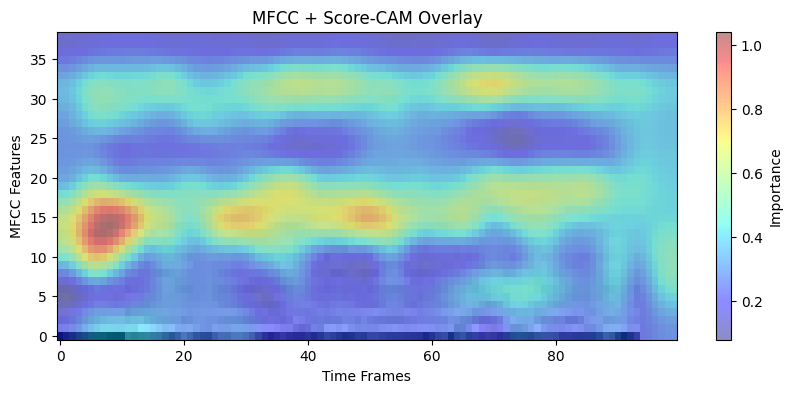

In [ ]:
# Overlay Heatmap
plt.figure(figsize=(10,4))

# Original MFCC
plt.imshow(
    features,
    cmap="gray",
    origin="lower",
    aspect="auto"
)

# Score-CAM Overlay
plt.imshow(
    heatmap_resized,
    cmap="jet",
    alpha=0.45,
    origin="lower",
    aspect="auto"
)

plt.colorbar(label="Importance")

plt.title("MFCC + Score-CAM Overlay")

plt.xlabel("Time Frames")
plt.ylabel("MFCC Features")

plt.show()

In [ ]:
#Calculate Statistics
import numpy as np
import pandas as pd

peak_attention = float(np.max(heatmap_resized))
mean_attention = float(np.mean(heatmap_resized))
std_attention = float(np.std(heatmap_resized))

# Percentage of pixels with attention > 0.5
attention_threshold = 0.5
attention_coverage = (
    np.sum(heatmap_resized > attention_threshold)
    / heatmap_resized.size
) * 100

# Time frame with maximum attention
max_index = np.unravel_index(
    np.argmax(heatmap_resized),
    heatmap_resized.shape
)

important_feature = int(max_index[0])
important_frame = int(max_index[1])

print("Peak Attention      :", peak_attention)
print("Mean Attention      :", mean_attention)
print("Std Attention       :", std_attention)
print("Attention Coverage  :", attention_coverage, "%")
print("Most Important MFCC :", important_feature)
print("Most Important Time :", important_frame)

Peak Attention      : 1.0411088466644287
Mean Attention      : 0.3682229816913605
Std Attention       : 0.15438321232795715
Attention Coverage  : 18.487179487179485 %
Most Important MFCC : 14
Most Important Time : 8


In [ ]:
# Generate prediction for the current audio
prediction = classifier(feature_maps, training=False)

prediction_probability = float(prediction.numpy()[0][0])

# Binary prediction
if prediction_probability >= 0.5:
    prediction_label = "REAL"
else:
    prediction_label = "FAKE"

# Confidence
confidence = max(
    prediction_probability,
    1 - prediction_probability
) * 100

# Voice Integrity Score
voice_integrity = prediction_probability * 100

# Risk Level
if voice_integrity >= 80:
    risk = "LOW RISK (Likely Genuine)"
elif voice_integrity >= 50:
    risk = "MEDIUM RISK (Suspicious)"
else:
    risk = "HIGH RISK (Likely AI Generated)"

# Automatic interpretation
interpretation = (
    f"The model focused mainly on MFCC feature "
    f"{important_feature} around time frame "
    f"{important_frame}. "
    f"Attention coverage was {attention_coverage:.2f}% "
    f"with a peak activation of {peak_attention:.2f}. "
    f"This indicates that these acoustic regions had "
    f"the strongest influence on the prediction."
)

print(interpretation)

The model focused mainly on MFCC feature 14 around time frame 8. Attention coverage was 18.49% with a peak activation of 1.04. This indicates that these acoustic regions had the strongest influence on the prediction.


In [ ]:
#CREATE REPORT
report = {
    "Prediction": prediction_label,
    "Confidence (%)": round(confidence,2),
    "Voice Integrity Score": round(voice_integrity,2),
    "Risk Level": risk,
    "Peak Attention": round(peak_attention,4),
    "Mean Attention": round(mean_attention,4),
    "Attention Coverage (%)": round(attention_coverage,2),
    "Most Important MFCC": important_feature,
    "Most Important Time Frame": important_frame,
    "Interpretation": interpretation
}

In [ ]:
print("="*55)
print("          VOCATRUST AI REPORT")
print("="*55)

for key,value in report.items():
    print(f"{key:<28}: {value}")

print("="*55)

          VOCATRUST AI REPORT
Prediction                  : REAL
Confidence (%)              : 99.99
Voice Integrity Score       : 99.99
Risk Level                  : LOW RISK (Likely Genuine)
Peak Attention              : 1.0411
Mean Attention              : 0.3682
Attention Coverage (%)      : 18.49
Most Important MFCC         : 14
Most Important Time Frame   : 8
Interpretation              : The model focused mainly on MFCC feature 14 around time frame 8. Attention coverage was 18.49% with a peak activation of 1.04. This indicates that these acoustic regions had the strongest influence on the prediction.
